<div dir="rtl" align="right">

# فصل دوم: ماتریس‌ها

این نوت‌بوک مفاهیم فصل دوم را به‌صورت عددی/نمادین و تصویری پیاده‌سازی می‌کند:  
**تعاریف و اعمال روی ماتریس‌ها**،  
**ترانهاده و خواص آن**،  
**نشان (Trace)**،  
**ماتریس‌های خاص** (صفر، همانی، قطری، مثلثی، ماتریس واحد U و ماتریس مرکز C)،  
**ماتریس‌های متقارن/پادمتقارن/خودتوان/متعامد**،  
**بازتاب هوس‌هولدر و ماتریس هِلمِرت**،  
**افراز ماتریس و ضرب بلوکی**،  
**حاصل‌ضرب کرونکر**،  
و **اشکال درجه‌دوم و معین/نیمه‌معین بودن**.

</div>


In [97]:

import numpy as np
import numpy.linalg as LA
import sympy as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio

sp.init_printing()

def almost_equal(a,b,tol=1e-9):
    a = np.array(a, dtype=float)
    b = np.array(b, dtype=float)
    return np.allclose(a, b, atol=tol, rtol=0)

def show(name, arr):
    print(f"{name} =\n{np.array(arr, dtype=float)}\n")

def plot_linear_transform(A, grid_lim=3):
    """تصویرسازی اثر یک ماتریس 2×2 روی شبکه مربعی."""
    A = np.asarray(A, dtype=float)
    xs = np.linspace(-grid_lim, grid_lim, 13)
    ys = np.linspace(-grid_lim, grid_lim, 13)
    fig, ax = plt.subplots(figsize=(5,5))
    # شبکه اولیه
    for y in ys:
        ax.plot(xs, np.full_like(xs, y), linewidth=0.5)
    for x in xs:
        ax.plot(np.full_like(ys, x), ys, linewidth=0.5)
    # شبکه تصویرشده
    for y in ys:
        pts = np.vstack([xs, np.full_like(xs, y)])
        tpts = A @ pts
        ax.plot(tpts[0], tpts[1], linewidth=1.0)
    for x in xs:
        pts = np.vstack([np.full_like(ys, x), ys])
        tpts = A @ pts
        ax.plot(tpts[0], tpts[1], linewidth=1.0)
    # بردارهای پایه
    e1 = A @ np.array([[1],[0]], float)
    e2 = A @ np.array([[0],[1]], float)
    ax.arrow(0,0,e1[0,0],e1[1,0], head_width=0.15, length_includes_head=True)
    ax.arrow(0,0,e2[0,0],e2[1,0], head_width=0.15, length_includes_head=True)
    ax.text(e1[0,0]*1.05, e1[1,0]*1.05, 'A e1')
    ax.text(e2[0,0]*1.05, e2[1,0]*1.05, 'A e2')
    ax.set_aspect('equal', adjustable='box')
    ax.set_title('اثر تبدیل خطی A')
    plt.show()


<div dir="rtl" align="right">

## بخش ۱: تعاریف پایه و اعمال: جمع، ضرب عددی/ماتریسی، ضرب ماتریس در بردار

این بخش همان تعاریف و مثال‌های ابتدایی فصل را عددی ارائه می‌کند:  
**جمع/تفریق ماتریس‌های هم‌مرتبه**،  
**ضرب عدد در ماتریس**،  
**ضرب ماتریس در بردار**  
و **قابلیت‌پذیری ضرب**.

</div>


In [82]:

A = np.array([[2,1,-1],
              [-3,-1,2],
              [-2,1,2]], float)
B = np.array([[1,0,1],
              [1,2,0],
              [0,1,1]], float)
c = 3

show("A", A) , show("B", B)
show("A+B", A+B)
show("A-B", A-B)
show("cA", c*A)

x = np.array([1,2,3.0])
show("x",x)
show("Ax", A@x)

# AB != BA
AB = A@B
BA = B@A
show("AB", AB)
show("BA", BA)
print("آیا AB=BA ؟", almost_equal(AB, BA))


A =
[[ 2.  1. -1.]
 [-3. -1.  2.]
 [-2.  1.  2.]]

B =
[[1. 0. 1.]
 [1. 2. 0.]
 [0. 1. 1.]]

A+B =
[[ 3.  1.  0.]
 [-2.  1.  2.]
 [-2.  2.  3.]]

A-B =
[[ 1.  1. -2.]
 [-4. -3.  2.]
 [-2.  0.  1.]]

cA =
[[ 6.  3. -3.]
 [-9. -3.  6.]
 [-6.  3.  6.]]

x =
[1. 2. 3.]

Ax =
[1. 1. 6.]

AB =
[[ 3.  1.  1.]
 [-4.  0. -1.]
 [-1.  4.  0.]]

BA =
[[ 0.  2.  1.]
 [-4. -1.  3.]
 [-5.  0.  4.]]

آیا AB=BA ؟ False


<div dir="rtl" align="right">

## بخش ۲: ترانهاده و خواص آن، نشان (Trace)

مطابق کتاب داریم:  

<span dir="ltr">$$(A^{T})^{T} = A, \qquad (A+B)^{T} = A^{T}+B^{T}, \qquad (AB)^{T} = B^{T}A^{T}$$</span>  

همچنین:  

<span dir="ltr">$$\mathrm{tr}(A) = \sum_i a_{ii}, \qquad \mathrm{tr}(A^{T})=\mathrm{tr}(A), \qquad 
\mathrm{tr}(A+B)=\mathrm{tr}(A)+\mathrm{tr}(B), \qquad 
\mathrm{tr}(AB)=\mathrm{tr}(BA)$$</span>

</div>


In [83]:

def show(name, arr):
    print(f"{name} =\n{np.array(arr, dtype=float)}\n")

def almost_equal(a, b, tol=1e-9):
    return np.allclose(a, b, atol=tol, rtol=0)

show("A", A)
show("B", B)

# ترانهاده
AT = A.T
show("A^T", AT)

print("(A^T)^T = A ؟", almost_equal(AT.T, A))
print("(A+B)^T = A^T + B^T ؟", almost_equal((A+B).T, AT + B.T))

AB = A @ B
BA = B @ A
show("AB", AB)
show("BA", BA)

print("(AB)^T = B^T A^T ؟", almost_equal((AB).T, B.T @ AT))

# تعریف تابع نشان
def tr(M): 
    return float(np.trace(M))

print("tr(A) =", tr(A))
print("tr(A^T) =", tr(AT))
print("آیا tr(A)=tr(A^T) ؟", np.isclose(tr(A), tr(AT)))

print("tr(A+B) =", tr(A+B))
print("tr(A)+tr(B) =", tr(A)+tr(B))
print("آیا tr(A+B)=tr(A)+tr(B) ؟", np.isclose(tr(A+B), tr(A)+tr(B)))

print("tr(AB) =", tr(AB))
print("tr(BA) =", tr(BA))
print("آیا tr(AB)=tr(BA) ؟", np.isclose(tr(AB), tr(BA)))


A =
[[ 2.  1. -1.]
 [-3. -1.  2.]
 [-2.  1.  2.]]

B =
[[1. 0. 1.]
 [1. 2. 0.]
 [0. 1. 1.]]

A^T =
[[ 2. -3. -2.]
 [ 1. -1.  1.]
 [-1.  2.  2.]]

(A^T)^T = A ؟ True
(A+B)^T = A^T + B^T ؟ True
AB =
[[ 3.  1.  1.]
 [-4.  0. -1.]
 [-1.  4.  0.]]

BA =
[[ 0.  2.  1.]
 [-4. -1.  3.]
 [-5.  0.  4.]]

(AB)^T = B^T A^T ؟ True
tr(A) = 3.0
tr(A^T) = 3.0
آیا tr(A)=tr(A^T) ؟ True
tr(A+B) = 7.0
tr(A)+tr(B) = 7.0
آیا tr(A+B)=tr(A)+tr(B) ؟ True
tr(AB) = 3.0
tr(BA) = 3.0
آیا tr(AB)=tr(BA) ؟ True


<div dir="rtl" align="right">

## بخش ۳: ماتریس‌های خاص
#### صفر، همانی، قطری، بالا/پایین مثلثی، یکه

تعاریف و نمونه‌ها + ویژگی‌های ساده‌ی ضرب با <span dir="ltr">$I$</span>:

<span dir="ltr">$$
AI = A, \qquad IA = A
$$</span>

</div>


In [84]:
import numpy as np
from IPython.display import HTML, display

# ماتریس‌های خاص
Z   = np.zeros((3,3))                               # صفر
I   = np.eye(3)                                     # همانی
D   = np.diag([1,2,3])                              # قطری
Upp = np.array([[1,2,0],[0,3,4],[0,0,5]], float)    # بالا مثلثی 
Low = np.array([[1,0,0],[2,4,0],[3,0,5]], float)    # پایین مثلثی
U   = np.ones((3,3))                                # یکه

specials = [
    ("۰ (صفر)", Z),
    ("I (همانی)", I),
    ("D (قطری)", D),
    ("Upp (بالا مثلثی)", Upp),
    ("Low (پایین مثلثی)", Low),
    ("U (یکه)", U),
]

# قالب‌بندی برای آرایه‌ها
def fmt_array(M):
    def f(x):
        return f"{int(x)}" if abs(x - int(x)) < 1e-12 else f"{x:.2f}"
    return np.array2string(np.array(M, float), formatter={'float_kind':f}, 
                           max_line_width=80)

# جدول HTML
rows = []
for name, M in specials:
    AB = A @ M
    BA = M @ A
    row = f"""
      <tr>
        <td><b>{name}</b><pre>{fmt_array(M)}</pre></td>
        <td><b>A + M</b><pre>{fmt_array(A + M)}</pre></td>
        <td><b>A @ M</b><pre>{fmt_array(AB)}</pre></td>
        <td><b>M @ A</b><pre>{fmt_array(BA)}</pre></td>
      </tr>
    """
    rows.append(row)

html = f"""
<style>
.tbl-mats {{ border-collapse: separate; border-spacing: 12px; font-family: monospace; }}
.tbl-mats td {{ vertical-align: top; padding: 6px 10px; border: 1px solid #ddd; border-radius: 8px; text-align:left; }}
.tbl-mats th {{ padding: 6px 10px; border-bottom:2px solid #444; }}
.tbl-mats pre {{ margin: 6px 0 0 0; text-align:left; }}
</style>

<div dir="rtl" style="text-align:right">
  <h4>ماتریس مثال A</h4>
</div>

<pre style="padding:8px 12px; border:1px solid #ddd; border-radius:8px; text-align:left;">{fmt_array(A)}</pre>

<table class="tbl-mats">
  <thead>
    <tr>
      <th>ماتریس خاص</th>
      <th>A + M</th>
      <th>A @ M</th>
      <th>M @ A</th>
    </tr>
  </thead>
  <tbody>
    {''.join(rows)}
  </tbody>
</table>
"""

display(HTML(html))


ماتریس خاص,A + M,A @ M,M @ A
۰ (صفر)[[0 0 0] [0 0 0] [0 0 0]],A + M[[2 1 -1] [-3 -1 2] [-2 1 2]],A @ M[[0 0 0] [0 0 0] [0 0 0]],M @ A[[0 0 0] [0 0 0] [0 0 0]]
I (همانی)[[1 0 0] [0 1 0] [0 0 1]],A + M[[3 1 -1] [-3 0 2] [-2 1 3]],A @ M[[2 1 -1] [-3 -1 2] [-2 1 2]],M @ A[[2 1 -1] [-3 -1 2] [-2 1 2]]
D (قطری)[[1 0 0] [0 2 0] [0 0 3]],A + M[[3 1 -1] [-3 1 2] [-2 1 5]],A @ M[[2 2 -3] [-3 -2 6] [-2 2 6]],M @ A[[2 1 -1] [-6 -2 4] [-6 3 6]]
Upp (بالا مثلثی)[[1 2 0] [0 3 4] [0 0 5]],A + M[[3 3 -1] [-3 2 6] [-2 1 7]],A @ M[[2 7 -1] [-3 -9 6] [-2 -1 14]],M @ A[[-4 -1 3] [-17 1 14] [-10 5 10]]
Low (پایین مثلثی)[[1 0 0] [2 4 0] [3 0 5]],A + M[[3 1 -1] [-1 3 2] [1 1 7]],A @ M[[1 4 -5] [1 -4 10] [6 4 10]],M @ A[[2 1 -1] [-8 -2 6] [-4 8 7]]
U (یکه)[[1 1 1] [1 1 1] [1 1 1]],A + M[[3 2 0] [-2 0 3] [-1 2 3]],A @ M[[2 2 2] [-2 -2 -2] [1 1 1]],M @ A[[-3 1 3] [-3 1 3] [-3 1 3]]


<div dir="rtl" align="right">

## ماتریس مرکزی

برای nn مشاهده، ماتریس واحد را <span dir="ltr">$U \in \mathbb{R}^{n\times n}$</span> و ماتریس مرکزی را
<span dir="ltr">$C = I - \tfrac{1}{n}U$</span> تعریف می‌کنیم. خواص کلیدی:

<span dir="ltr">$$U^2 = nU,\qquad C^2 = C,\qquad UC = CU = 0,\qquad C\mathbf{1}=\mathbf{0}$$</span>

اثر روی داده‌ها: اگر <span dir="ltr">$X\in\mathbb{R}^{n\times p}$</span> باشد،  
<span dir="ltr">$$X_c = CX = \bigl(I-\tfrac{1}{n}U\bigr)X$$</span>
به‌ازای هر ستونِ XX، میانگین آن ستون را کم می‌کند ⇒ ستون‌های XcX_c **میانگین صفر** دارند.  
همچنین CC متقارن و خودتوان است.

</div>


In [85]:
from IPython.display import display, HTML

np.set_printoptions(suppress=True)

def show(title, M):
    print(f"{title} =\n{np.array(M, dtype=float)}\n")

# =====================
# بخش A) ماتریس مرکزی C
# =====================
n = 5
U = np.ones((n,n))
C = np.eye(n) - U/n

# مثال داده: X (n×p) با اعداد صحیح
X = np.array([[1,  2,  3],
              [4,  5,  6],
              [7,  8,  9],
              [2,  0, -1],
              [3,  1,  4]])

Xc = C @ X  # مرکزی کردن ستون‌ها

print("=== ماتریس مرکزی ===")
show("U", U)
show("C = I - (1/n)U", C)
print("خاصیت‌ها:")
print("U^2 = nU ؟", np.allclose(U@U, n*U))
print("C^2 = C ؟", np.allclose(C@C, C))
print("UC = 0 و CU = 0 ؟", np.allclose(U@C, 0) and np.allclose(C@U, 0))
print("C 1 = 0 ؟", np.allclose(C @ np.ones((n,1)), 0))
print()

show("X (داده‌ی نمونه)", X)
show("X_c = C X (ستون‌ها مرکز شده‌اند)", np.round(Xc, 6))
print("میانگین هر ستونِ X_c ≈ 0 ؟", np.allclose(Xc.mean(axis=0), 0, atol=1e-12))
print()

=== ماتریس مرکزی ===
U =
[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]

C = I - (1/n)U =
[[ 0.8 -0.2 -0.2 -0.2 -0.2]
 [-0.2  0.8 -0.2 -0.2 -0.2]
 [-0.2 -0.2  0.8 -0.2 -0.2]
 [-0.2 -0.2 -0.2  0.8 -0.2]
 [-0.2 -0.2 -0.2 -0.2  0.8]]

خاصیت‌ها:
U^2 = nU ؟ True
C^2 = C ؟ True
UC = 0 و CU = 0 ؟ True
C 1 = 0 ؟ True

X (داده‌ی نمونه) =
[[ 1.  2.  3.]
 [ 4.  5.  6.]
 [ 7.  8.  9.]
 [ 2.  0. -1.]
 [ 3.  1.  4.]]

X_c = C X (ستون‌ها مرکز شده‌اند) =
[[-2.4 -1.2 -1.2]
 [ 0.6  1.8  1.8]
 [ 3.6  4.8  4.8]
 [-1.4 -3.2 -5.2]
 [-0.4 -2.2 -0.2]]

میانگین هر ستونِ X_c ≈ 0 ؟ True



<div dir="rtl" align="right">

## تصویرسازی مرکزی سازی ستونی

- ماتریس \(C\) یک پروجکشن است که از هر ستون \(X\) میانگین آن را کم می‌کند.  
- پس از مرکزی سازی، میانگین هر ستون برابر صفر می‌شود:  

$$
\bar x_c = 0
$$

- در اسکتر دوبعدی، نقاط فقط جابه‌جا می‌شود تا مرکز آن‌ها روی مبدأ قرار گیرد.

</div>


Column means before: [3.4 3.2 4.2]
Column means after: [-0.  0.  0.]


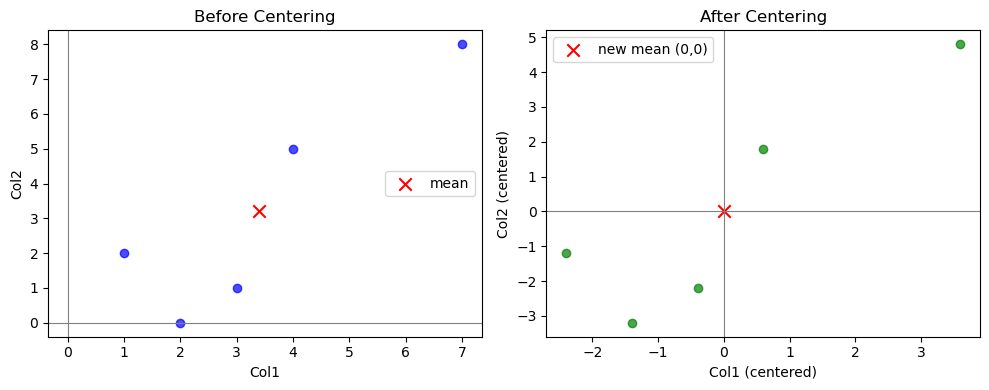

In [86]:

X = np.array([[1,  2,  3],
              [4,  5,  6],
              [7,  8,  9],
              [2,  0, -1],
              [3,  1,  4]])

n = X.shape[0]
U = np.ones((n,n))
C = np.eye(n) - U/n
Xc = C @ X

print("Column means before:", X.mean(axis=0))
print("Column means after:", Xc.mean(axis=0))

# اسکتر پلات برای ستون اول و دوم
fig, ax = plt.subplots(1,2,figsize=(10,4))

# قبل از مرکزی کردن
ax[0].scatter(X[:,0], X[:,1], color="blue", alpha=0.7)
ax[0].scatter([X[:,0].mean()],[X[:,1].mean()], color="red", marker="x", s=80, label="mean")
ax[0].axhline(0, color="gray", linewidth=0.8)
ax[0].axvline(0, color="gray", linewidth=0.8)
ax[0].set_title("Before Centering")
ax[0].set_xlabel("Col1")
ax[0].set_ylabel("Col2")
ax[0].legend()

# بعد از مرکزی کردن
ax[1].scatter(Xc[:,0], Xc[:,1], color="green", alpha=0.7)
ax[1].scatter([0],[0], color="red", marker="x", s=80, label="new mean (0,0)")
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].axvline(0, color="gray", linewidth=0.8)
ax[1].set_title("After Centering")
ax[1].set_xlabel("Col1 (centered)")
ax[1].set_ylabel("Col2 (centered)")
ax[1].legend()

plt.tight_layout()
plt.show()


<div dir="rtl" align="right">

## ماتریس‌های عملگر مقدماتی (سطری)

سه نوع عملگر مقدماتی سطری که با ضرب **سمت چپ** اعمال می‌شوند:

<ol>
<li>
<b>جابجایی سطر <span dir="ltr">$i$</span> و <span dir="ltr">$j$</span> — ماتریس جایگشتی <span dir="ltr">$P_{ij}$</span></b>
<p dir="ltr">
$$
\det(P_{ij})=-1, \qquad
P_{ij}^{-1}=P_{ij}.
$$
</p>
</li>

<li>
<b>ضرب سطر <span dir="ltr">$i$</span> در عدد <span dir="ltr">$\alpha \neq 0$</span> — ماتریس قطری <span dir="ltr">$D_i(\alpha)$</span></b>
<p dir="ltr">
$$
\det\!\big(D_i(\alpha)\big)=\alpha, \qquad
D_i(\alpha)^{-1}=D_i(\alpha^{-1}).
$$
</p>
</li>

<li>
<b>افزودن <span dir="ltr">$\alpha$</span> برابرِ سطر <span dir="ltr">$j$</span> به سطر <span dir="ltr">$i$</span> — ماتریس <span dir="ltr">$E_{ij}(\alpha)=I+\alpha\,e_i e_j^{T}$</span></b>
<p dir="ltr">
$$
\det\!\big(E_{ij}(\alpha)\big)=1, \qquad
E_{ij}(\alpha)^{-1}=E_{ij}(-\alpha).
$$
</p>
</li>
</ol>

</div>


In [87]:
# =======================================
# بخش B) عملگرهای مقدماتی سطری روی A (3×3)
# =======================================
A = np.array([[2, -1,  3],
              [0,  4,  1],
              [5,  2, -2]], float)

print("=== عملگرهای مقدماتی سطری ===")
show("A", A)
detA = round(LA.det(A))

# 1) جابجایی سطرهای 1 و 3 (اندیس 0 و 2 در پایتون)
P13 = np.eye(3); P13[[0,2]] = P13[[2,0]]
A_swap = P13 @ A
print("Swap سطر 1 و 3:")
show("P13", P13)
show("P13 @ A", A_swap)
print("det(P13) =", round(LA.det(P13)))
print("det(A_swap) ?= -det(A):", round(LA.det(A_swap)), " ?= ", -detA, "\n")

# 2) ضرب سطر 2 در α=3
alpha = 3
D2 = np.eye(3); D2[1,1] = alpha
A_scale = D2 @ A
print(f"Scale سطر 2 در α={alpha}:")
show("D2(α)", D2)
show("D2 @ A", A_scale)
print("det(D2) =", round(LA.det(D2)))
print("det(D2 @ A) ?= α·det(A):", round(LA.det(A_scale)), " ?= ", alpha*detA, "\n")

# 3) سطر 1 ← سطر 1 + (-2) × سطر 2
beta = -2
E12 = np.eye(3); E12[0,1] = beta
A_add = E12 @ A
print(f"Row-add: سطر 1 ← سطر 1 + ({beta})×سطر 2:")
show("E12(β)", E12)
show("E12 @ A", A_add)
print("det(E12) =", round(LA.det(E12)))
print("det(E12 @ A) ?= det(A):", round(LA.det(A_add)), " ?= ", detA, "\n")

# وارون‌ها
print("وارون‌ها:")
print("P13^{-1} = P13 ؟", np.allclose(LA.inv(P13), P13))
print("D2(α)^{-1} = D2(1/α) ؟", np.allclose(LA.inv(D2), np.diag([1,1/alpha,1])))
print("E12(β)^{-1} = E12(-β) ؟", np.allclose(LA.inv(E12), np.eye(3) - np.outer(np.eye(3)[:,0], np.eye(3)[:,1])*beta))


=== عملگرهای مقدماتی سطری ===
A =
[[ 2. -1.  3.]
 [ 0.  4.  1.]
 [ 5.  2. -2.]]

Swap سطر 1 و 3:
P13 =
[[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]

P13 @ A =
[[ 5.  2. -2.]
 [ 0.  4.  1.]
 [ 2. -1.  3.]]

det(P13) = -1
det(A_swap) ?= -det(A): 85  ?=  85 

Scale سطر 2 در α=3:
D2(α) =
[[1. 0. 0.]
 [0. 3. 0.]
 [0. 0. 1.]]

D2 @ A =
[[ 2. -1.  3.]
 [ 0. 12.  3.]
 [ 5.  2. -2.]]

det(D2) = 3
det(D2 @ A) ?= α·det(A): -255  ?=  -255 

Row-add: سطر 1 ← سطر 1 + (-2)×سطر 2:
E12(β) =
[[ 1. -2.  0.]
 [ 0.  1.  0.]
 [ 0.  0.  1.]]

E12 @ A =
[[ 2. -9.  1.]
 [ 0.  4.  1.]
 [ 5.  2. -2.]]

det(E12) = 1
det(E12 @ A) ?= det(A): -85  ?=  -85 

وارون‌ها:
P13^{-1} = P13 ؟ True
D2(α)^{-1} = D2(1/α) ؟ True
E12(β)^{-1} = E12(-β) ؟ True


<div dir="rtl" align="right">

## ماتریس‌های متقارن، پادمتقارن و خودتوان

- **ماتریس متقارن (Symmetric):**  
  $$A^{T} = A$$  

- **ماتریس پادمتقارن (Skew-symmetric):**  
  $$A^{T} = -A$$  

- **ماتریس خودتوان (Idempotent):**  
  $$A^{2} = A$$  

</div>


In [88]:
import numpy as np

def show(name, M):
    print(f"{name} =\n{np.array(M, dtype=float)}\n")

# --- ۱) متقارن ---
A_sym = np.array([[2, 1, 3],
                  [1, 4, 0],
                  [3, 0, 5]])

show("ماتریس متقارن A", A_sym)
print("ترانهاده A =\n", A_sym.T)
print("آیا A = A^T ؟", np.allclose(A_sym, A_sym.T))
print("-"*40)

# --- ۲) پادمتقارن ---
A_skew = np.array([[ 0, -2,  4],
                   [ 2,  0, -1],
                   [-4,  1,  0]])

show("ماتریس پادمتقارن A", A_skew)
print("ترانهاده A =\n", A_skew.T)
print("آیا A^T = -A ؟", np.allclose(A_skew.T, -A_skew))
print("-"*40)

# --- ۳) خودتوان ---
A_idem = np.array([[1, 0, 0],
                   [0, 0, 0],
                   [0, 0, 0]])

show("ماتریس خودتوان A", A_idem)
print("A^2 =\n", A_idem @ A_idem)
print("آیا A^2 = A ؟", np.allclose(A_idem @ A_idem, A_idem))


ماتریس متقارن A =
[[2. 1. 3.]
 [1. 4. 0.]
 [3. 0. 5.]]

ترانهاده A =
 [[2 1 3]
 [1 4 0]
 [3 0 5]]
آیا A = A^T ؟ True
----------------------------------------
ماتریس پادمتقارن A =
[[ 0. -2.  4.]
 [ 2.  0. -1.]
 [-4.  1.  0.]]

ترانهاده A =
 [[ 0  2 -4]
 [-2  0  1]
 [ 4 -1  0]]
آیا A^T = -A ؟ True
----------------------------------------
ماتریس خودتوان A =
[[1. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

A^2 =
 [[1 0 0]
 [0 0 0]
 [0 0 0]]
آیا A^2 = A ؟ True


<div dir="rtl" align="right">

## ماتریس تصویر (Projection Matrix)

ماتریس تصویر، داده‌ها را روی یک زیرفضای خاص **پروجکشن** می‌کند.  
برای ماتریس تصویر <span dir="ltr">$P$</span> داریم:

- خاصیت خودتوان:  
<span dir="ltr">$$P^2 = P$$</span>

- اگر پروجکشن متعامد باشد (orthogonal projection)، متقارن هم هست:  
<span dir="ltr">$$P^T = P$$</span>

- مقادیر ویژهٔ ماتریس تصویر فقط <span dir="ltr">0</span> یا <span dir="ltr">1</span> هستند.  

- رتبهٔ آن برابر با بُعد زیرفضای تصویر است و:  
<span dir="ltr">$$\operatorname{rank}(P) = \operatorname{tr}(P)$$</span>

</div>


ماتریس تصویر P =
[[0.5 0.5]
 [0.5 0.5]]

آیا P^2 = P ؟ True
آیا P^T = P ؟ True
مقادیر ویژه: [1. 0.]
rank(P) = 1   trace(P) = 1.0


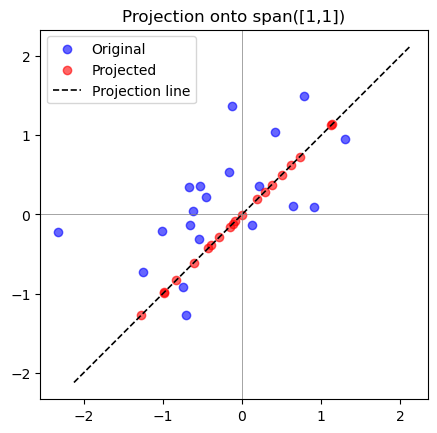

In [89]:

def show(name, M):
    print(f"{name} =\n{np.round(M,3)}\n")

# مثال: پروجکشن در R^2 روی خطی که بردار جهت‌اش u=[1,1]^T است
u = np.array([1,1], float)
u = u / LA.norm(u)   # نرمال‌سازی
P = np.outer(u,u)    # ماتریس پروجکشن

show("ماتریس تصویر P", P)

# خاصیت‌ها
print("آیا P^2 = P ؟", np.allclose(P@P, P))
print("آیا P^T = P ؟", np.allclose(P.T, P))
print("مقادیر ویژه:", np.round(LA.eigvals(P),3))
print("rank(P) =", LA.matrix_rank(P), "  trace(P) =", np.round(np.trace(P)))

# ------------------ نمایش تصویری ------------------
# چند نقطهٔ تصادفی در R^2
rng = np.random.default_rng(0)
X = rng.normal(size=(20,2))

X_proj = X @ P.T   # پروجکشن روی خط u

fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(X[:,0], X[:,1], c="blue", alpha=0.6, label="Original")
ax.scatter(X_proj[:,0], X_proj[:,1], c="red", alpha=0.6, label="Projected")

# خط u (جهت پروجکشن)
t = np.linspace(-3,3,10)
ax.plot(t*u[0], t*u[1], "k--", lw=1.2, label="Projection line")

ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set_aspect("equal")
ax.set_title("Projection onto span([1,1])")
ax.legend()
plt.show()


<div dir="rtl" align="right">

## پروژکشن قائم روی یک صفحه در  $\,\mathbb{R}^3\,$

</div>


In [90]:
import plotly.graph_objects as go

# --- تعریف ماتریس پروژکشن روی صفحه n·x=0 با نرمال n=[1,1,1] ---
n = np.array([1., 1., 1.])
P = np.eye(3) - np.outer(n, n)/(n@n)

# نقاط نمونه
rng = np.random.default_rng(0)
X = rng.normal(size=(20,3))
X_proj = (P @ X.T).T

# --- نمودار تعاملی ---
fig = go.Figure()

# نقاط اصلی
fig.add_trace(go.Scatter3d(
    x=X[:,0], y=X[:,1], z=X[:,2],
    mode='markers',
    marker=dict(size=4, color='blue'),
    name="Original"
))

# نقاط پروژکت‌شده
fig.add_trace(go.Scatter3d(
    x=X_proj[:,0], y=X_proj[:,1], z=X_proj[:,2],
    mode='markers',
    marker=dict(size=4, color='red'),
    name="Projected"
))

# خطوط وصل‌کننده x → Px برای چند نمونه
for i in range(6):
    fig.add_trace(go.Scatter3d(
        x=[X[i,0], X_proj[i,0]],
        y=[X[i,1], X_proj[i,1]],
        z=[X[i,2], X_proj[i,2]],
        mode='lines',
        line=dict(color='gray', width=2),
        showlegend=False
    ))

# صفحه n·x=0 (x+y+z=0) با یک مش
xx = np.linspace(-3,3,15)
yy = np.linspace(-3,3,15)
XX, YY = np.meshgrid(xx,yy)
ZZ = -(XX+YY)
fig.add_trace(go.Surface(x=XX, y=YY, z=ZZ, opacity=0.3, colorscale='Greens', showscale=False, name="Plane"))

fig.update_layout(
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="z",
        aspectmode="cube"
    ),
    title="Orthogonal Projection onto plane n=[1,1,1]"
)
import plotly.io as pio
pio.renderers.default = "notebook"

fig.show()


<div dir="rtl" align="right">

## ماتریس متعامد (Orthogonal Matrix)

ماتریس متعامد <span dir="ltr">$Q \in \mathbb{R}^{n \times n}$</span>، ماتریسی است که ستون‌ها و سطرهای آن یک مجموعهٔ قائم‌نرمال را تشکیل می‌دهند.  

خواص کلیدی:  

- <span dir="ltr">$$Q^{T} Q = I \quad \text{و} \quad Q Q^{T} = I$$</span>  
- معکوس ماتریس برابر ترانهادهٔ آن است: <span dir="ltr">$$Q^{-1} = Q^{T}$$</span>  
- ضرب یک بردار در ماتریس متعامد طول بردار را تغییر نمی‌دهد (حفظ نرم):  
  <span dir="ltr">$$\|Qx\| = \|x\| \quad \forall x$$</span>  
- دترمینان ماتریس متعامد برابر <span dir="ltr">+1</span> یا <span dir="ltr">-1</span> است (دوران یا بازتاب).

</div>


Q (ماتریس دوران 45 درجه) =
[[ 0.707 -0.707]
 [ 0.707  0.707]]

Q^T Q =
 [[ 1. -0.]
 [-0.  1.]]
آیا Q^T Q = I ؟ True
det(Q) = 1.0
آیا Q^-1 = Q^T ؟ True


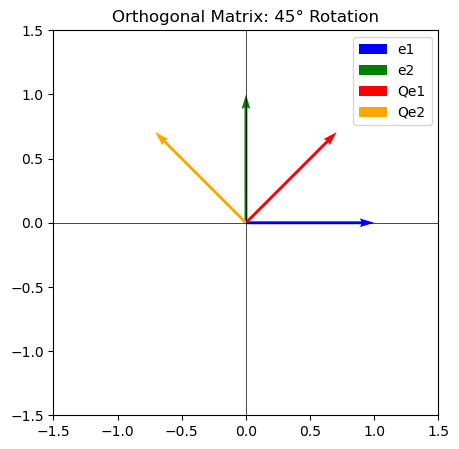

In [91]:
import numpy as np
import numpy.linalg as LA
import matplotlib.pyplot as plt

def show(name, M):
    print(f"{name} =\n{np.round(M,3)}\n")

# مثال: ماتریس دوران در R^2 با زاویه 45 درجه
theta = np.pi/4
Q = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

show("Q (ماتریس دوران 45 درجه)", Q)

# بررسی خواص
print("Q^T Q =\n", np.round(Q.T @ Q, 3))
print("آیا Q^T Q = I ؟", np.allclose(Q.T @ Q, np.eye(2)))
print("det(Q) =", round(LA.det(Q),3))
print("آیا Q^-1 = Q^T ؟", np.allclose(LA.inv(Q), Q.T))

# ---- تصویرسازی ----
# بردارهای پایه
e1 = np.array([1,0])
e2 = np.array([0,1])

# دوران بردارهای پایه
e1_rot = Q @ e1
e2_rot = Q @ e2

fig, ax = plt.subplots(figsize=(5,5))
ax.quiver(0,0,e1[0],e1[1],angles="xy",scale_units="xy",scale=1,color="blue",label="e1")
ax.quiver(0,0,e2[0],e2[1],angles="xy",scale_units="xy",scale=1,color="green",label="e2")
ax.quiver(0,0,e1_rot[0],e1_rot[1],angles="xy",scale_units="xy",scale=1,color="red",label="Qe1")
ax.quiver(0,0,e2_rot[0],e2_rot[1],angles="xy",scale_units="xy",scale=1,color="orange",label="Qe2")

ax.set_xlim(-1.5,1.5)
ax.set_ylim(-1.5,1.5)
ax.axhline(0,color="black",linewidth=0.5)
ax.axvline(0,color="black",linewidth=0.5)
ax.set_aspect("equal")
ax.legend()
ax.set_title("Orthogonal Matrix: 45° Rotation")
plt.show()


In [92]:
# نمایشی سه‌بعدی و تعاملی/متحرّک از خواص ماتریس متعامد با Plotly
# - مثال عددی: دورانِ 3بعدی حول بردار u = (1,1,1)/√3 با زاویه θ = 60°
# - نمایش: بردارهای پایه و تصویرشان، نقاط روی کرهٔ واحد و تصویرشان (کره ثابت می‌ماند)،
#   راستی‌آزمایی‌های Q^T Q = I ، det(Q)=+1 و حفظِ طول ||Qx||=||x||.
#
# نکته: اگر خروجی در نوت‌بوک نشان داده نشد، renderer را به "iframe" تغییر دهید.

import plotly.graph_objects as go
import plotly.io as pio

# تنظیم رندرر (در صورت نیاز یکی از این‌ها را فعال کنید)
try:
    pio.renderers.default = "notebook_connected"
except Exception:
    pio.renderers.default = "iframe"  # fallback مطمئن

# ---------- ساخت ماتریس دوران سه‌بعدی با فرمول رودریگز ----------
def rotation_matrix(axis, theta):
    """Rotation matrix in R^3: rotate by angle theta around unit axis (Rodrigues)."""
    axis = np.array(axis, dtype=float)
    axis = axis / LA.norm(axis)
    x, y, z = axis
    c = np.cos(theta); s = np.sin(theta); C = 1 - c
    R = np.array([
        [c + x*x*C,     x*y*C - z*s,  x*z*C + y*s],
        [y*x*C + z*s,   c + y*y*C,    y*z*C - x*s],
        [z*x*C - y*s,   z*y*C + x*s,  c + z*z*C ]
    ])
    return R

# محور و زاویه‌ی دوران (مثال عددی)
u = np.array([1., 1., 1.])
theta_final = np.deg2rad(60.0)   # 60 degrees
Q = rotation_matrix(u, theta_final)

# ---------- راستی‌آزمایی خواص ----------
print("ویژگی‌های ماتریس متعامد (مثال Q):")
print("آیا Q^T Q = I ؟", np.allclose(Q.T @ Q, np.eye(3)))
print("det(Q) =", float(np.round(LA.det(Q), 6)))
# نمونه‌ی حفظِ طول روی چند بردار تصادفی
rng = np.random.default_rng(0)
for i in range(3):
    x = rng.normal(size=3)
    lhs = LA.norm(Q @ x)
    rhs = LA.norm(x)
    print(f"حفظ طول (نمونه {i+1}): ||Qx||≈||x|| ؟", np.allclose(lhs, rhs))

# ---------- داده‌ها برای نمایش ----------
# بردارهای پایه و تصویرشان
e1, e2, e3 = np.eye(3)
Qe1, Qe2, Qe3 = Q @ e1, Q @ e2, Q @ e3

# چند نقطه روی کرهٔ واحد (برای نشان دادن اینکه کره تحت Q ثابت می‌ماند)
phi = np.linspace(0, np.pi, 18)
psi = np.linspace(0, 2*np.pi, 36)
PHI, PSI = np.meshgrid(phi, psi)
X = np.sin(PHI) * np.cos(PSI)
Y = np.sin(PHI) * np.sin(PSI)
Z = np.cos(PHI)
# اعمال Q روی مشِ کره
XYZ = np.stack([X, Y, Z], axis=-1)                   # shape: (36,18,3)
XYZ_rot = XYZ @ Q.T                                   # اعمال Q
Xr, Yr, Zr = XYZ_rot[...,0], XYZ_rot[...,1], XYZ_rot[...,2]

# چند نقطهٔ تصادفی در فضا و تصویرشان
Pts = rng.normal(size=(20,3))
Pts_rot = (Q @ Pts.T).T

# ---------- انیمیشن: از θ=0 تا θ=60° ----------
thetas = np.linspace(0, theta_final, 40)
frames = []
for th in thetas:
    Rt = rotation_matrix(u, th)
    # بردارهای دوران‌داده‌شده
    e1_t, e2_t, e3_t = Rt @ e1, Rt @ e2, Rt @ e3
    # کرهٔ دوران‌داده‌شده (در حقیقت ثابت می‌ماند، ولی برای نمایش فرایند از Rt استفاده می‌کنیم)
    S_rot = XYZ @ Rt.T
    Xt, Yt, Zt = S_rot[...,0], S_rot[...,1], S_rot[...,2]
    # نقاط تصادفی دوران‌داده‌شده
    Pts_t = (Rt @ Pts.T).T

    frames.append(go.Frame(
        data = [
            # بردارهای پایهِ دوران‌داده‌شده (به‌صورت segment از مبدا تا نقطه)
            go.Scatter3d(x=[0, e1_t[0]], y=[0, e1_t[1]], z=[0, e1_t[2]],
                         mode="lines+markers", line=dict(color="red", width=6),
                         marker=dict(size=3), name="Q e1", showlegend=False),
            go.Scatter3d(x=[0, e2_t[0]], y=[0, e2_t[1]], z=[0, e2_t[2]],
                         mode="lines+markers", line=dict(color="green", width=6),
                         marker=dict(size=3), name="Q e2", showlegend=False),
            go.Scatter3d(x=[0, e3_t[0]], y=[0, e3_t[1]], z=[0, e3_t[2]],
                         mode="lines+markers", line=dict(color="orange", width=6),
                         marker=dict(size=3), name="Q e3", showlegend=False),
            # کره‌ی دوران‌داده‌شده
            go.Surface(x=Xt, y=Yt, z=Zt, opacity=0.25, colorscale="Blues",
                       showscale=False, name="Rotated Sphere", showlegend=False),
            # نقاط تصادفی دوران‌داده‌شده
            go.Scatter3d(x=Pts_t[:,0], y=Pts_t[:,1], z=Pts_t[:,2],
                         mode="markers", marker=dict(size=3, color="purple"),
                         name="Q x", showlegend=False),
        ],
        name=f"theta={np.rad2deg(th):.1f}°"
    ))

# ---------- شکل پایه ----------
fig = go.Figure()

# محورهای مختصات (بردارهای پایه بدون دوران)
fig.add_trace(go.Scatter3d(x=[0, e1[0]], y=[0, e1[1]], z=[0, e1[2]],
                           mode="lines+markers", line=dict(color="red", width=6),
                           marker=dict(size=3), name="e1"))
fig.add_trace(go.Scatter3d(x=[0, e2[0]], y=[0, e2[1]], z=[0, e2[2]],
                           mode="lines+markers", line=dict(color="green", width=6),
                           marker=dict(size=3), name="e2"))
fig.add_trace(go.Scatter3d(x=[0, e3[0]], y=[0, e3[1]], z=[0, e3[2]],
                           mode="lines+markers", line=dict(color="orange", width=6),
                           marker=dict(size=3), name="e3"))

# کرهٔ واحد (اصلی)
fig.add_trace(go.Surface(x=X, y=Y, z=Z, opacity=0.25, colorscale="Greys",
                         showscale=False, name="Unit Sphere"))

# نقاط تصادفی اصلی و تصویر نهایی‌شان
fig.add_trace(go.Scatter3d(x=Pts[:,0], y=Pts[:,1], z=Pts[:,2],
                           mode="markers", marker=dict(size=3, color="blue"),
                           name="x"))
fig.add_trace(go.Scatter3d(x=Pts_rot[:,0], y=Pts_rot[:,1], z=Pts_rot[:,2],
                           mode="markers", marker=dict(size=3, color="purple"),
                           name="Q x (final)"))

# بردارهای پایهٔ دوران‌یافته (حالت نهایی) و کرهٔ دوران‌یافته (همان کره)
fig.add_trace(go.Scatter3d(x=[0, Qe1[0]], y=[0, Qe1[1]], z=[0, Qe1[2]],
                           mode="lines+markers", line=dict(color="red", width=6, dash="dash"),
                           marker=dict(size=3), name="Q e1"))
fig.add_trace(go.Scatter3d(x=[0, Qe2[0]], y=[0, Qe2[1]], z=[0, Qe2[2]],
                           mode="lines+markers", line=dict(color="green", width=6, dash="dash"),
                           marker=dict(size=3), name="Q e2"))
fig.add_trace(go.Scatter3d(x=[0, Qe3[0]], y=[0, Qe3[1]], z=[0, Qe3[2]],
                           mode="lines+markers", line=dict(color="orange", width=6, dash="dash"),
                           marker=dict(size=3), name="Q e3"))

# کرهٔ دوران‌یافته‌ی نهایی (همان کره؛ برای تاکید)
fig.add_trace(go.Surface(x=Xr, y=Yr, z=Zr, opacity=0.25, colorscale="Blues",
                         showscale=False, name="Rotated Sphere (final)"))

# ---------- انیمیشن ----------
fig.frames = frames
fig.update_layout(
    title="Orthogonal Matrix in 3D: Rotation about u = (1,1,1)/√3 by 60°",
    scene=dict(
        xaxis_title="x", yaxis_title="y", zaxis_title="z",
        aspectmode="cube",
        xaxis=dict(range=[-1.6,1.6]), yaxis=dict(range=[-1.6,1.6]), zaxis=dict(range=[-1.6,1.6])
    ),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    updatemenus=[dict(
        type="buttons",
        showactive=True,
        buttons=[
            dict(label="Play", method="animate",
                 args=[None, {"frame": {"duration": 70, "redraw": True},
                              "fromcurrent": True, "transition": {"duration": 0}}]),
            dict(label="Pause", method="animate",
                 args=[[None], {"frame": {"duration": 0, "redraw": False},
                                "mode": "immediate",
                                "transition": {"duration": 0}}])
        ]
    )],
    sliders=[dict(
        steps=[dict(method="animate",
                    args=[[f.name], {"mode": "immediate", "frame": {"duration": 0, "redraw": True},
                                     "transition": {"duration": 0}}],
                    label=f.name) for f in frames],
        active=len(frames)-1
    )]
)

fig.show()


ویژگی‌های ماتریس متعامد (مثال Q):
آیا Q^T Q = I ؟ True
det(Q) = 1.0
حفظ طول (نمونه 1): ||Qx||≈||x|| ؟ True
حفظ طول (نمونه 2): ||Qx||≈||x|| ؟ True
حفظ طول (نمونه 3): ||Qx||≈||x|| ؟ True


<div dir="rtl" align="right">

## بخش ۴: افراز ماتریس و ضرب بلوکی

با سازگاری ابعاد، ضرب بلوکی به صورت زیر است:

<span dir="ltr">$$
\big[\,A \ \ B\,\big]
\begin{bmatrix}
X\\[4pt]
Y
\end{bmatrix}
\;=\;
AX + BY
$$</span>

و برای ضرب دو ماتریسِ بلوکی/سازگار، درایهٔ بلوکِ سطرِ \(i\) و ستونِ \(k\) برابر است با:

<span dir="ltr">$$
C_{ik} \;=\; \sum_{j}\, A_{ij}\, B_{jk}.
$$</span>

</div>


In [93]:

A11 = np.array([[1,2],[3,4.]])
A12 = np.array([[0,1],[2,3.]])
A21 = np.array([[1,0]])
A22 = np.array([[2,2]])
Ablk = np.block([[A11, A12],
                 [A21, A22]])

X = np.array([[1],[2]])
Y = np.array([[3],[4]])
left = np.hstack([A11, A12]) @ np.vstack([X,Y])
right = A11@X + A12@Y
print("ضرب بلوکی سازگار؟", almost_equal(left, right))
show("A (بلوک‌بندی‌شده)", Ablk)


ضرب بلوکی سازگار؟ True
A (بلوک‌بندی‌شده) =
[[1. 2. 0. 1.]
 [3. 4. 2. 3.]
 [1. 0. 2. 2.]]



<div dir="rtl" align="right">

## بخش ۵: حاصل‌ضرب کرونکر (Kronecker Product)

حاصل‌ضرب کرونکر دو ماتریس <span dir="ltr">$A \otimes B$</span> به این صورت تعریف می‌شود:  
هر درایهٔ <span dir="ltr">$a_{ij}$</span> از ماتریس <span dir="ltr">$A$</span> در کل ماتریس <span dir="ltr">$B$</span> ضرب می‌شود.  

<span dir="ltr">$$
A =
\begin{bmatrix}
a & b \\
c & d
\end{bmatrix}, \quad
B =
\begin{bmatrix}
e & f \\
g & h
\end{bmatrix}
$$</span>

آنگاه:

<span dir="ltr">$$
A \otimes B =
\begin{bmatrix}
aB & bB \\
cB & dB
\end{bmatrix}.
$$</span>

</div>


In [94]:
# مثال کتاب
A2 = np.array([[11,12],[21,22.]])
B2 = np.array([[1,0],[0,1.]])
K = np.kron(A2, B2)
show("A ⊗ B", K)


A ⊗ B =
[[11.  0. 12.  0.]
 [ 0. 11.  0. 12.]
 [21.  0. 22.  0.]
 [ 0. 21.  0. 22.]]



<div dir="rtl" align="right">

## بخش ۶: اشکال درجه دوم و ماتریس‌های معین مثبت/نیمه‌معین

**شکل درجه دوم** برای یک بردار و ماتریس متقارن به صورت زیر تعریف می‌شود:

$$
q(x) = x^{T} A x, \qquad x \in \mathbb{R}^n
$$


---

### ماتریس معین مثبت (Positive Definite)

یک ماتریس متقارن \(A\) معین مثبت است اگر:

- برای هر بردار غیرصفر:
<span dir="ltr">$$x^{T} A x > 0$$</span>
- همهٔ مقادیر ویژهٔ \(A\) مثبت باشند.
- دترمینان همهٔ زیرماتریس‌های اصلی مثبت باشند.

---

### ماتریس نیمه‌معین مثبت (Positive Semi-definite)

یک ماتریس متقارن \(A\) نیمه‌معین مثبت است اگر:

- برای هر \(x\):  
<span dir="ltr">$$x^{T} A x \ge 0$$</span>
- همهٔ مقادیر ویژهٔ \(A\) نامنفی باشند.

</div>


In [95]:

def check_matrix(A, name):
    print(f"--- {name} ---")
    print("ماتریس:\n", A)
    eigvals = LA.eigvals(A)
    print("مقادیر ویژه =", np.round(eigvals, 3))
    # تست روی چند بردار تصادفی
    rng = np.random.default_rng(0)
    for i in range(3):
        x = rng.normal(size=A.shape[0])
        q = x.T @ A @ x
        print(f"x={np.round(x,2)},  x^T A x = {np.round(q,3)}")
    print()

# مثال ۱: ماتریس معین مثبت (مثلاً ماتریس قطری با درایه‌های مثبت)
A_pos = np.array([[2, 0],
                  [0, 3]])
check_matrix(A_pos, "مثال معین مثبت")

# مثال ۲: ماتریس نیمه‌معین مثبت (مثلاً B^T B)
B = np.array([[1,2,3],
              [0,1,4]])
A_semi = B.T @ B   # این همیشه نیمه‌معین مثبت است
check_matrix(A_semi, "مثال نیمه‌معین مثبت")


--- مثال معین مثبت ---
ماتریس:
 [[2 0]
 [0 3]]
مقادیر ویژه = [2. 3.]
x=[ 0.13 -0.13],  x^T A x = 0.084
x=[0.64 0.1 ],  x^T A x = 0.853
x=[-0.54  0.36],  x^T A x = 0.966

--- مثال نیمه‌معین مثبت ---
ماتریس:
 [[ 1  2  3]
 [ 2  5 10]
 [ 3 10 25]]
مقادیر ویژه = [29.58 -0.    1.42]
x=[ 0.13 -0.13  0.64],  x^T A x = 9.081
x=[ 0.1  -0.54  0.36],  x^T A x = 0.843
x=[ 1.3   0.95 -0.7 ],  x^T A x = 4.67



<div dir="rtl" align="right">

## نمایش سه‌بعدی تعاملی شکل درجه‌دوم

- سطح $$z = x^{T} A x$$
- اگر $A$ **معین‌مثبت (PD)** باشد (همه‌ی مقدارویژه‌ها بزرگتر از صفر): سطح مثل «کاسه»‌ی بیضوی است.  
- اگر $A$ **نیمه‌معین‌مثبت (PSD)** باشد (مقدارویژه‌ای برابر صفر): در راستای ویژه‌ی متناظر، سطح «تخت/شیار» می‌شود.

در نمودار تعاملی زیر با اسلایدر مقدارویژه‌ی کوچک را از $1$ به $0$ می‌بریم تا گذار PD→PSD مشاهده شود.

</div>


In [96]:

try:
    pio.renderers.default = "notebook_connected"
except Exception:
    pio.renderers.default = "iframe"

# --- تعریف خانواده‌ای از ماتریس‌ها: A(t) = R^T diag(λ1, λ2(t)) R
# R یک دوران ثابت برای اینکه محورهای اصلیِ سطح، با محورهای x,y یکی نباشند (قابل دیدن‌تر)
theta = np.deg2rad(30)
R = np.array([[ np.cos(theta), -np.sin(theta)],
              [ np.sin(theta),  np.cos(theta)]])
lam1 = 3.0                     # مقدارویژه‌ی بزرگ (ثابت >0)
def A_of_t(t):
    lam2 = max(0.0, 1.0 - t)   # از 1 → 0 (PD → PSD)
    D = np.diag([lam1, lam2])
    return R.T @ D @ R

# --- گرید x,y و تابع z = x^T A x
xr = np.linspace(-2.5, 2.5, 120)
yr = np.linspace(-2.5, 2.5, 120)
X, Y = np.meshgrid(xr, yr)
XY = np.stack([X, Y], axis=-1)   # [...,2]

def z_from_A(A):
    # z[i,j] = [x y] A [x;y]
    AX = XY @ A.T
    return (XY * AX).sum(axis=-1)

# --- قاب‌های انیمیشن برای t=0..1
num_steps = 20
ts = np.linspace(0, 1, num_steps)
frames = []
for t in ts:
    A = A_of_t(t)
    Z = z_from_A(A)
    lam2 = max(0.0, 1.0 - t)
    pd_label = "PD" if lam2 > 1e-12 else "PSD"
    title = f"z = xᵀ A x   |   eigenvalues ≈ [{lam1:.2f}, {lam2:.2f}]   →   {pd_label}"
    frames.append(go.Frame(
        data=[go.Surface(x=X, y=Y, z=Z, colorscale="Viridis", showscale=False,
                         contours={"z": {"show": True, "usecolormap": True, "project_z": True}})],
        name=f"{t:.2f}",
        layout=go.Layout(title=title)
    ))

# شکل اولیه (t=0: PD با [3,1])
A0 = A_of_t(0.0)
Z0 = z_from_A(A0)

fig = go.Figure(
    data=[go.Surface(x=X, y=Y, z=Z0, colorscale="Viridis", showscale=False,
                     contours={"z": {"show": True, "usecolormap": True, "project_z": True}})],
    layout=go.Layout(
        title="z = xᵀ A x   |   eigenvalues ≈ [3.00, 1.00]   →   PD",
        scene=dict(
            xaxis_title="x", yaxis_title="y", zaxis_title="z",
            aspectmode="cube",
            xaxis=dict(range=[xr.min(), xr.max()]),
            yaxis=dict(range=[yr.min(), yr.max()]),
            zaxis=dict(range=[0, 25])  # بسته به مقیاس داده، قابل تغییر
        ),
        updatemenus=[dict(
            type="buttons",
            showactive=True,
            y=1.05, x=1.0, xanchor="right",
            buttons=[
                dict(label="Play", method="animate",
                     args=[None, {"frame": {"duration": 120, "redraw": True},
                                  "fromcurrent": True, "transition": {"duration": 0}}]),
                dict(label="Pause", method="animate",
                     args=[[None], {"frame": {"duration": 0, "redraw": False},
                                    "mode": "immediate", "transition": {"duration": 0}}])
            ]
        )],
        sliders=[dict(
            active=0,
            steps=[dict(method="animate",
                        args=[[f"{t:.2f}"],
                              {"mode":"immediate","frame":{"duration":0,"redraw":True},
                               "transition":{"duration":0}}],
                        label=f"{t:.2f}") for t in ts],
            y=0.0
        )]
    ),
    frames=frames
)

fig.show()
